<a href="https://colab.research.google.com/github/Alexandra1031/Metodos-numericos-l/blob/main/Diferencias_Divididas_MoralesNoriegaAlexandra.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#<font color="pink">**Diferencias Divididas**
### Algoritmo 3.2 (Burden, p. 93)

Métodos Numéricos I  
Alexandra Morales Noriega


Se conoce el valor de una función $f$ en $n+1$ nodos distintos $x_0, x_1, \dots, x_n$ y se busca el polinomio $P_n$ de grado a lo sumo $n$ que cumple

$$P_n(x_k) = f(x_k), \qquad k = 0, 1, \dots, n.$$

Se desea obtener sus **coeficientes** escritos en la forma de Newton.



###Método

El polinomio de interpolación se escribe como

$$P_n(x) = F_{0,0} + \sum_{i=1}^{n} F_{i,i} \prod_{j=0}^{i-1}(x - x_j),$$

donde $F_{i,i} = f[x_0, x_1, \dots, x_i]$ son las **diferencias divididas**. Se calculan con

$$F_{i,0} = f(x_i), \qquad F_{i,j} = \frac{F_{i,j-1} - F_{i-1,j-1}}{x_i - x_{i-j}}$$

para $i = 1, \dots, n$ y $j = 1, \dots, i$. Los coeficientes del polinomio son los números de la **diagonal**: $F_{0,0}, F_{1,1}, \dots, F_{n,n}$.

In [1]:
import numpy as np               # arreglos y matrices numéricas
import pandas as pd              # para mostrar la tabla F con formato
import sympy as sp               # para escribir el polinomio de forma simbólica
import matplotlib.pyplot as plt  # para graficar

In [2]:
def diferencias_divididas(xs, fs):
    """
    Fórmula de las diferencias divididas de Newton (Algoritmo 3.2, Burden).

    ENTRADA: xs -> nodos x_0, ..., x_n
             fs -> valores f(x_0), ..., f(x_n)
    SALIDA:  F  -> tabla de diferencias divididas;
                   los coeficientes están en la diagonal F[i, i]
    """
    n = len(xs) - 1                    # n+1 es el número de nodos
    F = np.zeros((n + 1, n + 1))       # tabla F inicializada en ceros
    F[:, 0] = fs                       # primera columna: F_{i,0} = f(x_i)

    # construyendo la tabla por filas
    for i in range(1, n + 1):          # i = 1, ..., n (fila)
        for j in range(1, i + 1):      # j = 1, ..., i (columna)
            # Diferencia dividida de orden j
            F[i, j] = (F[i, j - 1] - F[i - 1, j - 1]) / (xs[i] - xs[i - j])

    # salida
    return F

###Ejemplo 1 (Burden, p. 94)

Se completa la tabla de diferencias divididas con los datos de la Tabla 3.10 y se construye el polinomio de interpolación con todos los puntos:

| $x$ | $f(x)$ |
|---|---|
| 1.0 | 0.7651977 |
| 1.3 | 0.6200860 |
| 1.6 | 0.4554022 |
| 1.9 | 0.2818186 |
| 2.2 | 0.1103623 |

In [3]:
xs = [1.0, 1.3, 1.6, 1.9, 2.2]                                # nodos (Tabla 3.10)
fs = [0.7651977, 0.6200860, 0.4554022, 0.2818186, 0.1103623]  # valores f(x_i)

F = diferencias_divididas(xs, fs)   # se construye la tabla F

# Se muestra F como tabla (equivale a la Tabla 3.11 del libro)
tabla = pd.DataFrame(F, index=xs, columns=[f"f[...] orden {j}" for j in range(len(xs))])
tabla.where(np.tril(np.ones_like(F, dtype=bool))).style.format("{:.7f}", na_rep="")

,f[...] orden 0,f[...] orden 1,f[...] orden 2,f[...] orden 3,f[...] orden 4
1.000000,0.7651977,,,,
1.300000,0.6200860,-0.4837057,,,
1.600000,0.4554022,-0.5489460,-0.1087339,,
1.900000,0.2818186,-0.5786120,-0.0494433,0.0658784,
2.200000,0.1103623,-0.5715210,0.0118183,0.0680685,0.0018251


La primera columna son los valores $f(x_i)$ y cada columna siguiente contiene las diferencias divididas de un orden mayor. Los coeficientes del polinomio de Newton son los de la diagonal.

In [4]:
coeficientes = np.diag(F)   # diagonal de F: F00, F11, ..., Fnn
print("Coeficientes del polinomio de Newton:")
for k, c in enumerate(coeficientes):
    print(f"  F[{k},{k}] = {c:.7f}")

Coeficientes del polinomio de Newton:
  F[0,0] = 0.7651977
  F[1,1] = -0.4837057
  F[2,2] = -0.1087339
  F[3,3] = 0.0658784
  F[4,4] = 0.0018251


###Polinomio de Newton con sympy

Se define una función que toma los nodos y los coeficientes (la salida del algoritmo), escribe el polinomio de Newton y lo grafica.

In [5]:
def polinomio_newton(xs, coef, grafica=True):
    """
    Construye y grafica el polinomio de Newton con sympy.

    ENTRADA: xs   -> nodos x_0, ..., x_n
             coef -> coeficientes F_{0,0}, ..., F_{n,n} (diagonal de F)
    SALIDA:  P    -> polinomio de Newton (expresión de sympy)
    """
    x = sp.symbols("x")             # variable simbólica
    P = coef[0]                     # primer término: F_{0,0}
    producto = 1                    # producto (x - x_0)...(x - x_{i-1})
    for i in range(1, len(coef)):
        producto = producto * (x - xs[i - 1])
        P = P + coef[i] * producto  # se suma F_{i,i} * producto

    if grafica:
        f = sp.lambdify(x, P, "numpy")                    # sympy -> función numérica
        xx = np.linspace(min(xs) - 0.1, max(xs) + 0.1, 200)
        plt.plot(xx, f(xx), label="P(x)")                 # curva del polinomio
        plt.scatter(xs, fs, color="red", label="Nodos")   # datos originales
        plt.title("Polinomio de Newton")
        plt.xlabel("x")
        plt.ylabel("y")
        plt.grid(alpha=0.3)
        plt.legend()
        plt.show()
    return P

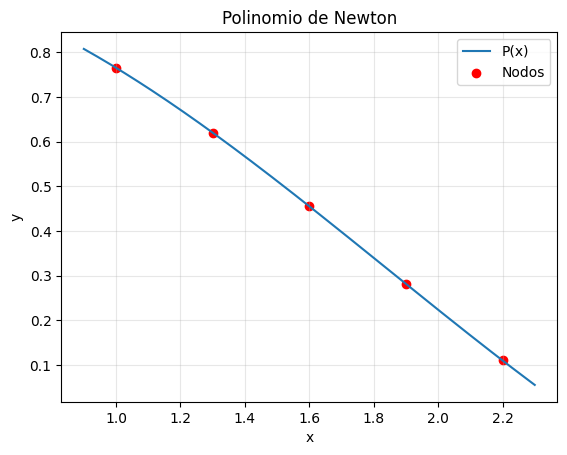

Forma de Newton:


-0.483705666666666⋅x + 0.00182510288066044⋅(x - 1.9)⋅(x - 1.6)⋅(x - 1.3)⋅(x -  ↪

↪ 1.0) + 0.0658783950617283⋅(x - 1.6)⋅(x - 1.3)⋅(x - 1.0) - 0.108733888888889⋅ ↪

↪ (x - 1.3)⋅(x - 1.0) + 1.24890336666667

Forma expandida:


                     4                       3                      2          ↪
0.00182510288066044⋅x  + 0.0552927983538978⋅x  - 0.343046604938247⋅x  + 0.0733 ↪

↪                                   
↪ 913477366034⋅x + 0.977735055967085

In [6]:
sp.init_printing()                          # muestra las expresiones en formato matemático
x = sp.symbols("x")

P = polinomio_newton(xs, coeficientes)      # polinomio en forma de Newton y gráfica

print("Forma de Newton:")
display(P)
print("Forma expandida:")
display(sp.expand(P))

In [7]:
# Se evalúa el polinomio en x = 1.5 y se compara con el libro
valor = P.subs(x, 1.5)
print(f"P4(1.5) = {float(valor):.7f}")
print("Valor en el libro: 0.5118200")

P4(1.5) = 0.5118200
Valor en el libro: 0.5118200


## Conclusión

La tabla obtenida coincide con la Tabla 3.11 del libro. Los coeficientes del polinomio de Newton, tomados de la diagonal, son

$$F_{0,0}=0.7651977,\; F_{1,1}=-0.4837057,\; F_{2,2}=-0.1087339,\; F_{3,3}=0.0658784,\; F_{4,4}=0.0018251$$

y el **polinomio de interpolación** es

$$P_4(x) = 0.7651977 - 0.4837057(x-1.0) - 0.1087339(x-1.0)(x-1.3) + 0.0658784(x-1.0)(x-1.3)(x-1.6) + 0.0018251(x-1.0)(x-1.3)(x-1.6)(x-1.9)$$

Además, $P_4(1.5) = 0.5118200$ coincide con el resultado del método de Neville, porque ambos métodos producen el mismo polinomio.